<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 14 · Boltzmann transport, thermoelectrics and the Edelstein effect

$L^{(n)}_{ab}=\frac{1}{VN_k}\sum(-\partial_Ef)(E-\mu)^n v_av_b$, so
$\sigma=L^{(0)}$, $S=-\frac{1}{k_BT}L^{(0)-1}L^{(1)}$ and $\kappa=(L^{(2)}-L^{(1)}L^{(0)-1}L^{(1)})/T$.
Edelstein: $\delta\langle O\rangle = \chi E$ with extrinsic (∝τ) and intrinsic interband parts.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline
from hopforge import response as R

## 1. Conductivity, Seebeck and the Wiedemann-Franz law

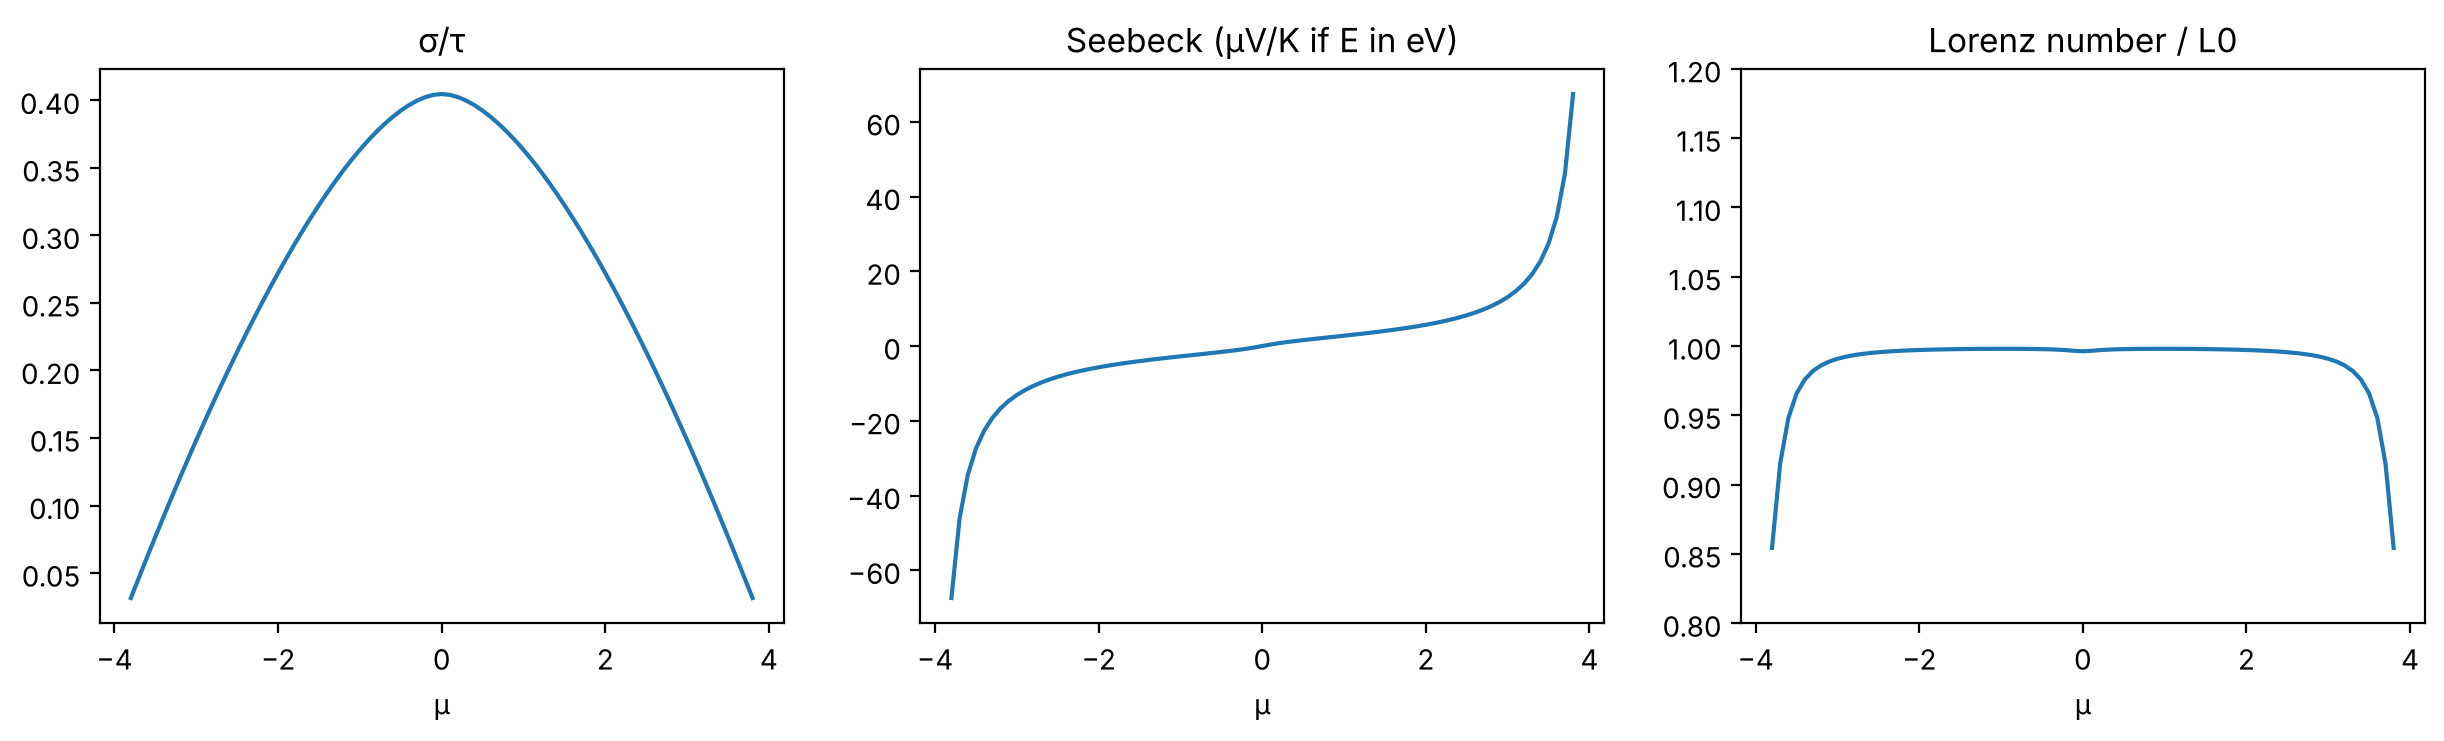

In [2]:
mus = np.linspace(-3.8, 3.8, 77)
r = R.boltzmann(M.square(), mus, kT=0.05, nk=200, n_jobs=-1)
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].plot(mus, r.sigma_over_tau[:, 0, 0]); ax[0].set_title("σ/τ")
ax[1].plot(mus, r.seebeck_uV_per_K[:, 0, 0]); ax[1].set_title("Seebeck (μV/K if E in eV)")
ax[2].plot(mus, r.lorenz / (np.pi**2/3)); ax[2].set_title("Lorenz number / L0"); ax[2].set_ylim(0.8, 1.2)
for a in ax: a.set_xlabel("μ")

## 2. Thermoelectric power factor of a two-band semiconductor

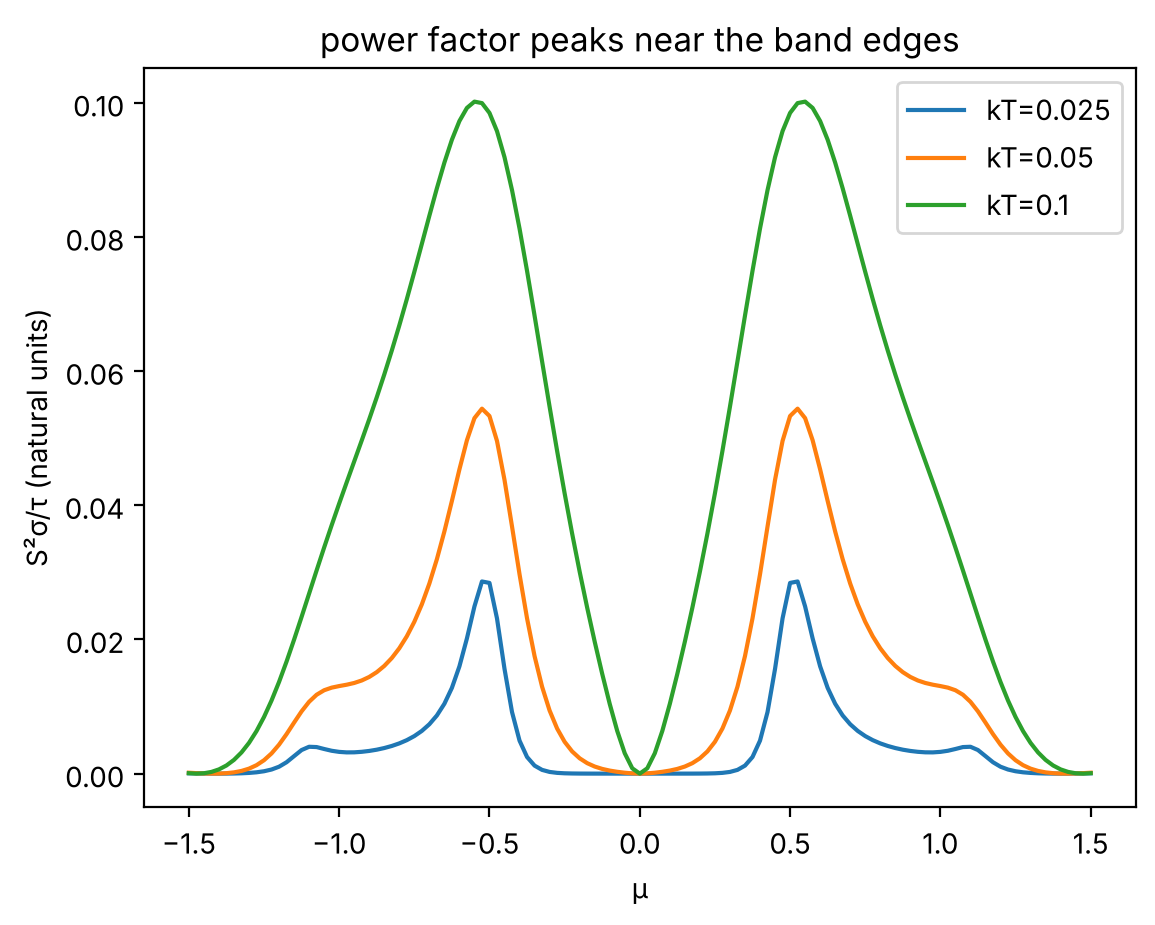

In [3]:
semi = M.honeycomb(delta=0.5)
mus = np.linspace(-1.5, 1.5, 121)
for kT in (0.025, 0.05, 0.1):
    r = R.boltzmann(semi, mus, kT=kT, nk=150, n_jobs=-1)
    pf = r.seebeck[:, 0, 0]**2 * r.sigma_over_tau[:, 0, 0]
    plt.plot(mus, pf, label=f"kT={kT}")
plt.legend(); plt.xlabel("μ"); plt.ylabel("S²σ/τ (natural units)"); plt.title("power factor peaks near the band edges");

## 3. Rashba-Edelstein effect: current-induced spin polarisation

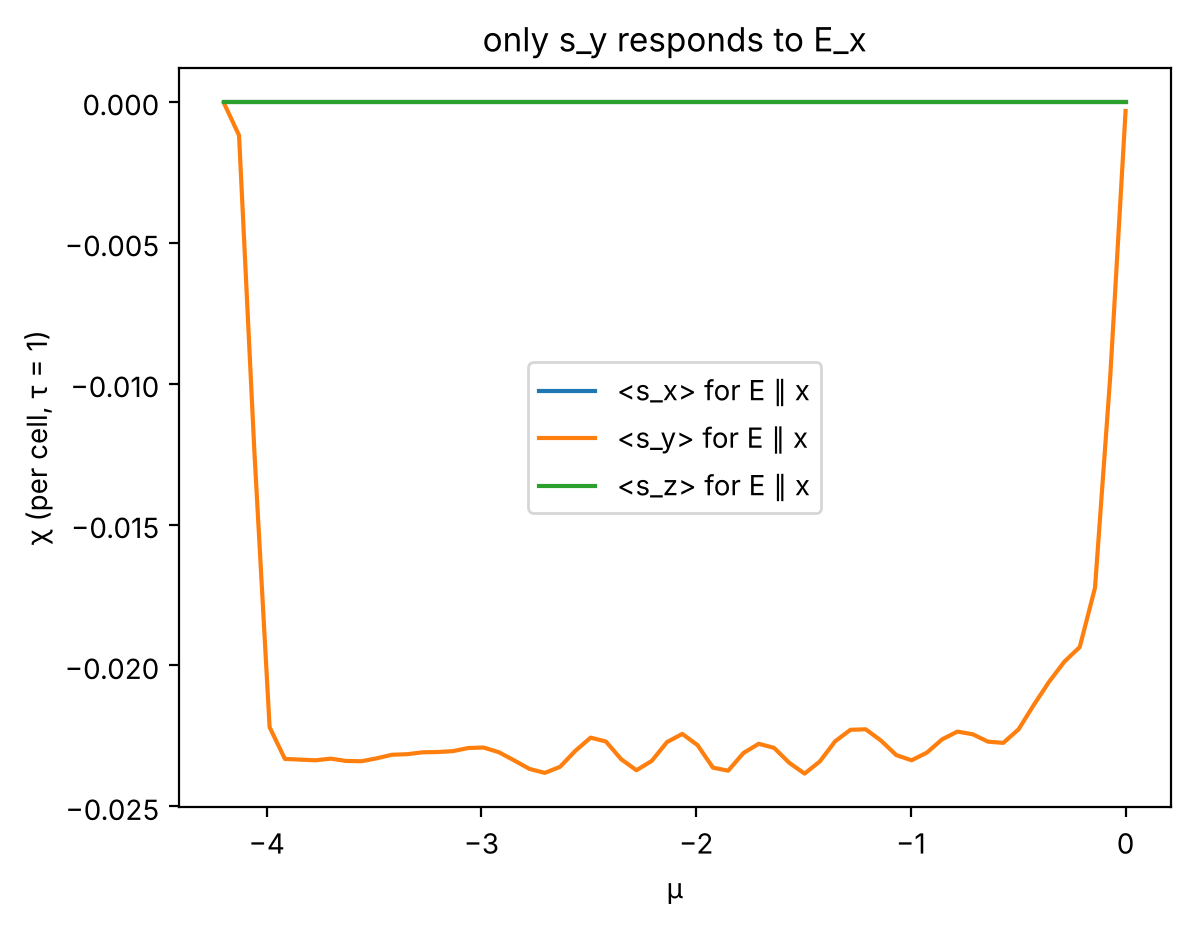

In [4]:
ra = M.rashba_square(alpha=0.3)
mus = np.linspace(-4.2, 0, 60)
for a in "xyz":
    e = R.edelstein(ra, ra.spin_operator(a), "x", mu=mus, kT=0.02, nk=150, n_jobs=-1)
    plt.plot(mus, e["total"], label=f"<s_{a}> for E ∥ x")
plt.legend(); plt.xlabel("μ"); plt.ylabel("χ (per cell, τ = 1)"); plt.title("only s_y responds to E_x");

## 4. Intrinsic (field-like vs damping-like) Edelstein in a Rashba ferromagnet

In [5]:
for J in (0.0, 0.3, 0.6):
    fm = M.rashba_square(alpha=0.3, J=J)
    e = R.edelstein(fm, fm.spin_operator('x'), "x", mu=-2.0, kT=0.02, nk=150, n_jobs=-1)
    print(f"J={J}: <s_x> extrinsic {e['extrinsic'][0]:+.5f}   intrinsic {e['intrinsic'][0]:+.5f}")

J=0.0: <s_x> extrinsic -0.00000   intrinsic -0.00000


J=0.3: <s_x> extrinsic +0.00000   intrinsic +0.00919


J=0.6: <s_x> extrinsic -0.00000   intrinsic +0.01209


## 5. Orbital Edelstein effect: the orbital Rashba model
A surface field breaks inversion and allows bond-odd hybridisation $\gamma\,\hat d_x$ between $p_z$ and $p_x$ (and $\hat d_y$ for $p_z$-$p_y$), which is the orbital Rashba effect (Park et al., PRB 2011). It produces an orbital Edelstein response even without spin-orbit coupling.

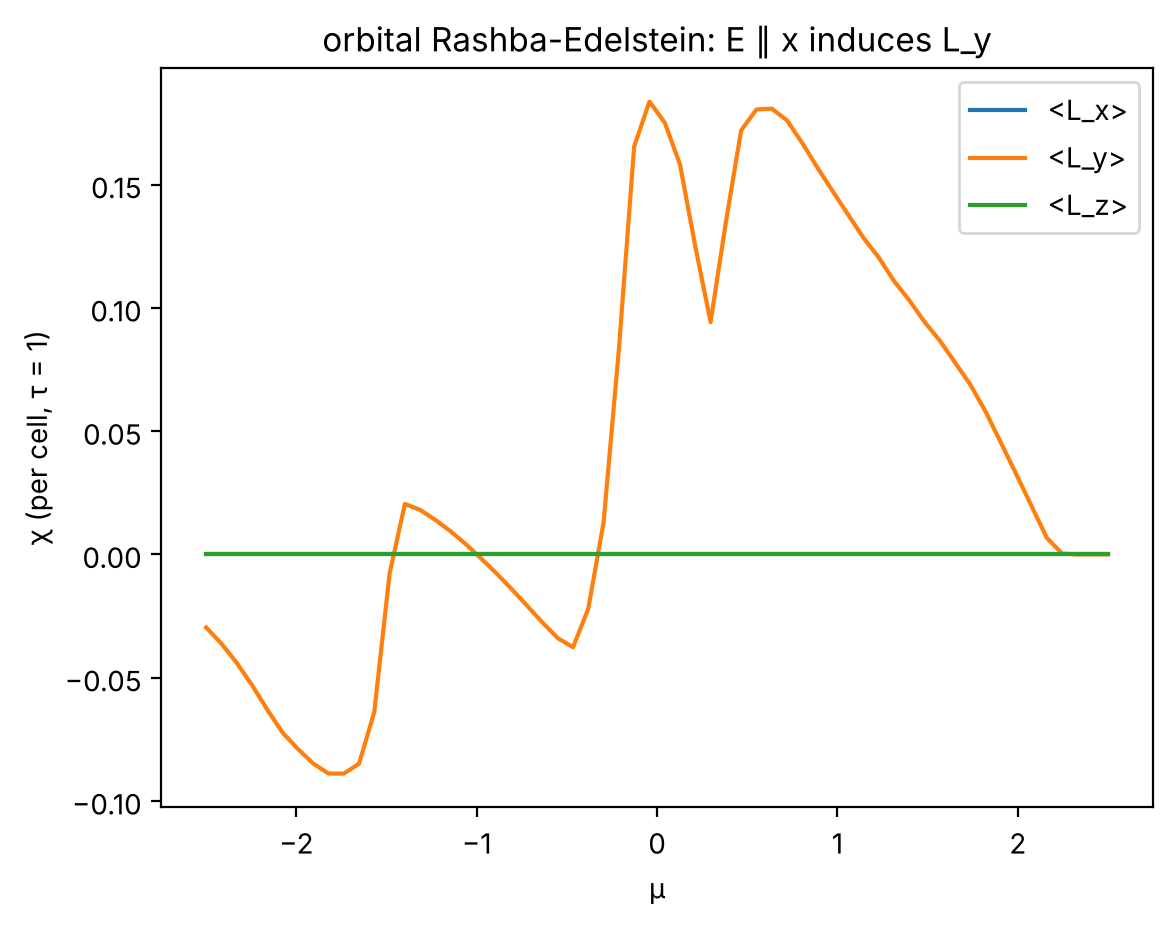

In [6]:
po = M.p_orbital_square()
gamma = 0.3
po.add_neighbors(lambda d: gamma * d[0], 1, ["X:pz"], ["X:px"])     # odd in d: inversion broken
po.add_neighbors(lambda d: gamma * d[1], 1, ["X:pz"], ["X:py"])
po.add_onsite(-0.5, "X:pz")                                          # crystal-field splitting
mus = np.linspace(-2.5, 2.5, 60)
for a in "xyz":
    e = R.edelstein(po, po.orbital_operator(a), "x", mu=mus, kT=0.02, nk=120, n_jobs=-1)
    plt.plot(mus, e["total"], label=f"<L_{a}>")
plt.legend(); plt.xlabel("μ"); plt.ylabel("χ (per cell, τ = 1)")
plt.title("orbital Rashba-Edelstein: E ∥ x induces L_y");

## Exercises
1. Convert σ/τ to S/m with `r.sigma_SI(tau_fs=10)` for a 3D model.
2. Find where |S| peaks relative to the band edge of the gapped honeycomb model.
3. Compare spin and orbital Edelstein responses of `M.p_orbital_square(lso=0.2)`.

---
## Quiz 14: Boltzmann and Edelstein

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [7]:
quiz = hf.Quiz(14)
quiz.interactive()

In [8]:
quiz.show()

=== Quiz 14: Boltzmann transport, thermoelectrics and the Edelstein effect ===

Q1. In the constant-relaxation-time approximation sigma_ab equals
   (a) e^2/h C
   (b) e^2 tau sum (-df/dE) v_a v_b / V
   (c) zero
   (d) sum f Omega

Q2. The Seebeck coefficient in Mott-like form is S ~
   (a) 1/T
   (b) sigma T
   (c) e/h
   (d) -(pi^2/3)(k_B^2 T / e) d ln sigma(E)/dE

Q3. For electron-like carriers (near a band bottom) the Seebeck coefficient is
   (a) zero
   (b) positive
   (c) negative
   (d) infinite

Q4. The Wiedemann-Franz law states kappa_e/(sigma T) =
   (a) e^2/h
   (b) pi^2/3 (k_B/e)^2
   (c) k_B/e
   (d) 1

Q5. Deviations from Wiedemann-Franz in hopforge's Boltzmann model appear when
   (a) tau changes
   (b) spin is included
   (c) kT is comparable to the energy scale of the band structure (non-degenerate)
   (d) never

Q6. The thermoelectric figure of merit is
   (a) e^2/h
   (b) S/T
   (c) sigma/kappa
   (d) zT = S^2 sigma T / (kappa_e + kappa_lattice)

Q7. Constant-tau B

In [9]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0